In [13]:
import pandas as pd
import numpy as np
reading_messy = pd.read_csv('aaus4_class_meter_readings_messy - aaus4_class_meter_readings_messy.csv')
treatment_messy = pd.read_csv('aaus4_class_treatment_samples_messy - aaus4_class_treatment_samples_messy.csv')
print(f"Meter Reading Messy Data Count {reading_messy.shape} and Treatment Messy Data Count {treatment_messy.shape}")
print(reading_messy.head(0).to_string())
print(treatment_messy.head(0).to_string())
print('curr dtype: ', str(reading_messy.curr_m3.dtypes))
print(reading_messy[['prev_m3','curr_m3']].isna().sum().to_dict())
#reading_messy.head(1)
#print(len(reading_messy))
#print(len(treatment_messy))
#treatment_messy.head(1)
#reading_messy.info
#treatment_messy.info

Meter Reading Messy Data Count (432, 11) and Treatment Messy Data Count (369, 11)
Empty DataFrame
Columns: [record_id, meter_id, read_date, branch, customer_segment, meter_type, prev_m3, curr_m3, status, source_system, collector_team]
Index: []
Empty DataFrame
Columns: [sample_id, sample_date, plant, district, sampling_point, treatment_type, chlorine_mg_l, turbidity_ntu, ph, analyst_team, result_status]
Index: []
curr dtype:  object
{'prev_m3': 0, 'curr_m3': 11}


In [14]:
s = pd.Series([12.0,None,18.8,24.0])
filled = s.fillna(s.median())
print(filled.tolist())
print('changed : ', int(s.isna().sum()))

[12.0, 18.8, 18.8, 24.0]
changed :  1


In [25]:
lab = treatment_messy.copy()
lab['chlorine_num'] = pd.to_numeric(lab.chlorine_mg_l,errors='coerce')
#lab['chlorine_fill'] = lab.groupby('plant')['chlorine_num'].transform(lamda x: x.fillna(x.median()))
#print('Remaining : ',int(lab.chlorine_fill.isna().sum()))

In [20]:
w = pd.read_csv('aaus4_class_maintenance_orders_messy - aaus4_class_maintenance_orders_messy.csv')
print("Length Od Data :", len(w))
print("Data Duplication : ", int(w.duplicated().sum()))

Length Od Data : 310
Data Duplication :  10


In [23]:
key_dup = w.duplicated(subset=['order_id'] , keep=False)
print('Raw With Repeted IDs : ' , int(key_dup.sum()))
print('Distinct Repitws ID ', w.loc[key_dup,'order_id'].nunique())

Raw With Repeted IDs :  20
Distinct Repitws ID  10


In [27]:
print(reading_messy[['prev_m3','curr_m3']]
.isna().sum().to_dict())
print('raw rows:', len(reading_messy))

{'prev_m3': 0, 'curr_m3': 11}
raw rows: 432


In [29]:
rates = (reading_messy.isna().mean()*100).round(1)
print(rates[rates>0].to_dict())

{'curr_m3': 2.5}


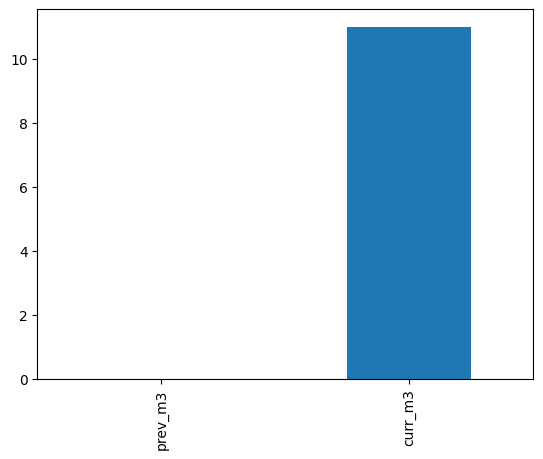

In [30]:
import matplotlib.pyplot as plt
reading_messy.isna().sum().loc[
  ['prev_m3','curr_m3']
].plot.bar()
plt.show()

In [33]:
m_required = reading_messy.dropna(subset=['curr_m3'])
print('before:', len(reading_messy))
print('after:', len(m_required))
print('dropped:', len(reading_messy)-len(m_required))

before: 432
after: 421
dropped: 11


In [34]:
ab = treatment_messy.copy()
lab['chlorine_num'] = pd.to_numeric(
lab.chlorine_mg_l, errors='coerce')
lab['chlorine_fill'] = lab.groupby('plant')[
'chlorine_num'].transform(
lambda x: x.fillna(x.median()))
print('remaining:', 
int(lab.chlorine_fill.isna().sum()))

remaining: 0


In [36]:
w = pd.read_csv('aaus4_class_maintenance_orders_messy - aaus4_class_maintenance_orders_messy.csv')
print('raw work orders:', len(w))
print('full duplicates:', int(w.duplicated().sum()))

raw work orders: 310
full duplicates: 10


In [37]:
key_dups = w.duplicated(subset=['order_id'], keep=False)
print('rows with repeated ID:', int(key_dups.sum()))
print('distinct repeated IDs:', w.loc[key_dups,
'order_id'].nunique())

rows with repeated ID: 20
distinct repeated IDs: 10


In [38]:
w_unique = w.drop_duplicates(
subset=['order_id'], keep='first').copy()
print('unique orders:', len(w_unique))
print('IDs unique:', w_unique.order_id.is_unique)

unique orders: 300
IDs unique: True


In [40]:
m_unique = reading_messy.drop_duplicates('record_id').copy()
m_unique['curr_num'] = pd.to_numeric(
m_unique.curr_m3, errors='coerce')
print('raw NA:', int(m_unique.curr_m3.isna().sum()))
print('coerced NA:', int(m_unique.curr_num.isna().sum()))

raw NA: 11
coerced NA: 19


In [41]:
w_unique['opened_dt'] = pd.to_datetime(
w_unique.opened_date, errors='coerce',
format='%Y-%m-%d')
print('invalid open dates:',
int(w_unique.opened_dt.isna().sum()))

invalid open dates: 5


In [42]:
priority = pd.Series(['1','2','bad','4'])
converted = pd.to_numeric(
priority, errors='coerce').astype('Int64')
print(converted.tolist())
print(str(converted.dtype))

[1, 2, <NA>, 4]
Int64


In [43]:
a = pd.read_csv('aaus4_class_asset_registry_messy.csv')
a['condition_clean'] = (
a.condition.str.strip().str.title())
print(a.condition_clean.value_counts()
.to_dict())

{'Critical': 51, 'Poor': 51, 'Fair': 43, 'Good': 43}


In [46]:
m_unique['branch_clean'] = (m_unique.branch.str.strip().str.title().replace({'Akakki':'Akaki'}))
print(sorted(m_unique.branch_clean.unique().tolist()))

['Akaki', 'Bole', 'Gullele', 'Kirkos', 'Lideta', 'Merkato']


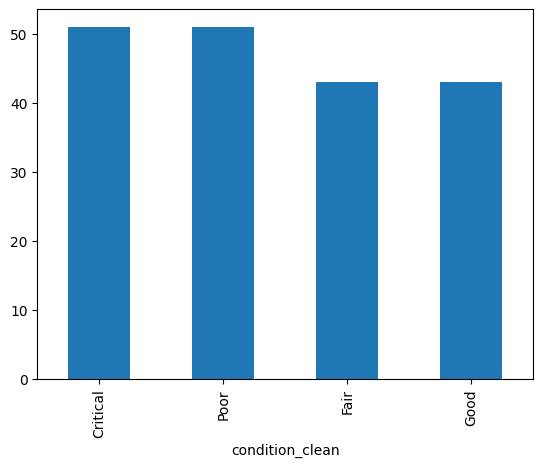

In [47]:
raw = a.condition.value_counts()
v = a.condition_clean
clean = v.value_counts()
raw.plot.bar()
clean.plot.bar()
plt.show()

In [48]:
m_unique['prev_num'] = pd.to_numeric(
m_unique.prev_m3, errors='coerce')
m_unique['usage_m3'] = (
m_unique.curr_num - m_unique.prev_num)
print('negative gaps:', int((m_unique.usage_m3<0).sum()))

negative gaps: 6


In [49]:
w_unique['closed_dt'] = pd.to_datetime(
w_unique.closed_date, errors='coerce', format='%Y-%m-%d')
w_unique['bad_dates'] = (
w_unique.opened_dt.isna() | w_unique.closed_dt.isna()
| (w_unique.closed_dt < w_unique.opened_dt))
print('date flags:', int(w_unique.bad_dates.sum()))

date flags: 8


In [50]:
w_unique['actual_cost'] = pd.to_numeric(
w_unique.actual_cost_etb, errors='coerce')
w_unique['bad_cost'] = (
w_unique.actual_cost.isna() | (w_unique.actual_cost < 0))
print('cost flags:', int(w_unique.bad_cost.sum()))

cost flags: 13


In [52]:
x = m_unique.usage_m3.dropna()
print(x.quantile([.25,.50,.75])
.round(1).to_dict())
print('max:', float(x.max()))

{0.25: 29.0, 0.5: 48.0, 0.75: 67.0}
max: 950.0


In [53]:
q1,q3 = x.quantile([.25,.75])
low,high = q1-1.5*(q3-q1),q3+1.5*(q3-q1)
print('IQR bounds:', 
round(low,1),round(high,1))
print('flagged:', 
int((~x.between(low,high)).sum()))

IQR bounds: -28.0 124.0
flagged: 6


In [54]:
values = np.array([2,4,8,80])
scenario = np.clip(values,0,10)
print('raw:', values.tolist())
print('scenario:', scenario.tolist())

raw: [2, 4, 8, 80]
scenario: [2, 4, 8, 10]


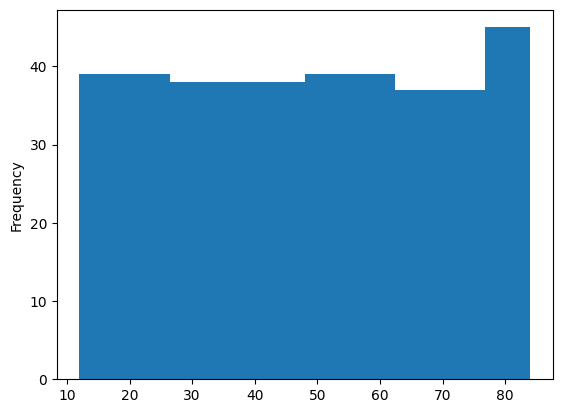

In [55]:
gap = m_unique.usage_m3
valid_gap = gap[
gap.between(0,200)]
valid_gap.plot.hist()
plt.show()

In [57]:
raw_n,clean_n = len(reading_messy),len(m_unique)
removed = raw_n - clean_n
print('raw / removed / retained:',
raw_n,removed,clean_n)
print('reconciles:', raw_n==removed+clean_n)

raw / removed / retained: 432 12 420
reconciles: True


In [60]:
# 1. Primary key uniqueness check
assert m_unique.record_id.is_unique
# 2. Reconciliation formula check
assert len(reading_messy) == len(m_unique) + 12
# 3. Foreign key / work order check
assert w_unique.order_id.is_unique
print('key and reconciliation checks: PASS')


key and reconciliation checks: PASS


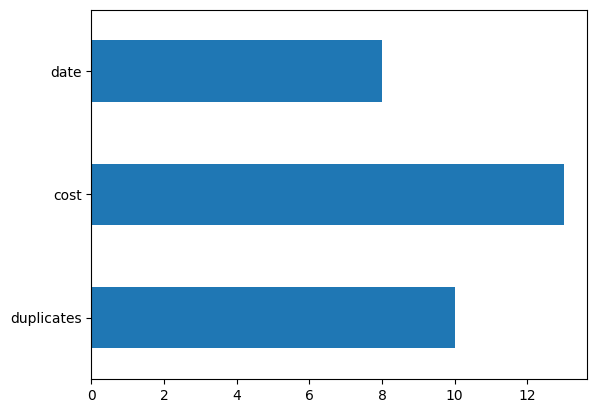

In [61]:
flags = pd.Series(
{'duplicates':10, 'cost':13,
'date':8})
flags.plot.barh()
plt.show()

In [63]:
x = m_unique.usage_m3.dropna()
print(x.quantile([.25,.50,.75])
.round(1).to_dict())
print('max:', float(x.max()))

{0.25: 29.0, 0.5: 48.0, 0.75: 67.0}
max: 950.0


In [64]:
x = m_unique.usage_m3.dropna()
print(x.quantile([.25,.50,.75])
.round(1).to_dict())
print('max:', float(x.max()))

{0.25: 29.0, 0.5: 48.0, 0.75: 67.0}
max: 950.0


In [65]:
q1,q3 = x.quantile([.25,.75])
low,high = q1-1.5*(q3-q1),q3+1.5*(q3-q1)
print('IQR bounds:', 
round(low,1),round(high,1))
print('flagged:', 
int((~x.between(low,high)).sum()))

IQR bounds: -28.0 124.0
flagged: 6


In [67]:
lab.turbidity_num.plot.box()
plt.ylabel('NTU')
plt.show()

AttributeError: 'DataFrame' object has no attribute 'turbidity_num'

In [78]:
values = np.array([2,4,8,80,560,890.00])
scenario = np.clip(values,0,10)
print('raw:', values.tolist())
print('scenario:', scenario.tolist())

raw: [2.0, 4.0, 8.0, 80.0, 560.0, 890.0]
scenario: [2.0, 4.0, 8.0, 10.0, 10.0, 10.0]


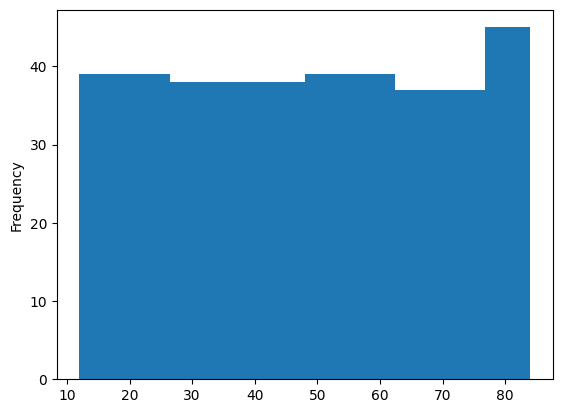

In [71]:
gap = m_unique.usage_m3
valid_gap = gap[
gap.between(0,200)]
valid_gap.plot.hist()
plt.show()

In [73]:
raw_n,clean_n = len(reading_messy),len(m_unique)
removed = raw_n - clean_n
print('raw / removed / retained:',
raw_n,removed,clean_n)
print('reconciles:', raw_n==removed+clean_n)

raw / removed / retained: 432 12 420
reconciles: True


In [75]:
# 1. Primary key uniqueness check
assert m_unique.record_id.is_unique
# 2. Reconciliation formula check
assert len(reading_messy) == len(m_unique) + 12
# 3. Foreign key / work order check
assert w_unique.order_id.is_unique
print('key and reconciliation checks: PASS')

key and reconciliation checks: PASS


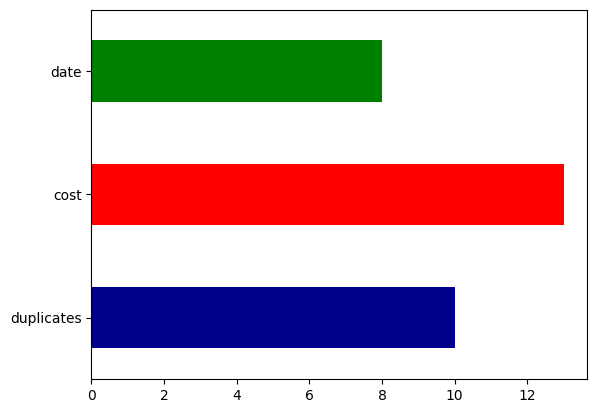

In [87]:
flags = pd.Series(
{'duplicates':10, 'cost':13,
'date':8})
flags.plot.barh(color=['darkblue', 'red', 'green'])
plt.show()

In [89]:
# Calculate consumption gap
meter_clean['usage'] = (meter_clean.curr_num - meter_clean.prev_num)
# Flag missing, negative, or excessive values
meter_clean['needs_review'] = (
meter_clean.usage.isna() |
(meter_clean.usage < 0) |
(meter_clean.usage > 200))
print('flagged:', int(meter_clean.needs_review.sum()))

NameError: name 'meter_clean' is not defined

In [ ]:
meter_valid = meter_clean.loc[~meter_clean.needs_review].copy()
# Audit dataset record counts
print('raw:', len(reading_messy))
print('retained:', len(meter_clean))
len(reading_messy)
len(meter_clean)
print('valid for usage:', len(meter_valid))

NameError: name 'meter_clean' is not defined

: 